Movie-Movie similarity graphs

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent
DATA_DIR = PROJECT_ROOT / "Data" / "ml-32m"

RATINGS_FILE = DATA_DIR / "ratings.csv"
MOVIES_FILE = DATA_DIR / "movies.csv"
LINKS_FILE = DATA_DIR / "links.csv"
TAGS_FILE = DATA_DIR / "tags.csv"

TOP_X = 1_000
MIN_SHARED = 2000
TOP_K = 15
CUTOFF = pd.Timestamp("2015-01-01")

CHUNK_SIZE = 1_000_000

movies = pd.read_csv(MOVIES_FILE)
movies["movieId"] = movies["movieId"].astype("int32")

print(movies.shape)
movies.head()

(87585, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [19]:
cutoff_ts = int(CUTOFF.timestamp())
print("Cutoff:", CUTOFF)

Cutoff: 2015-01-01 00:00:00


In [20]:
rating_counts = {}

for chunk in pd.read_csv(
    RATINGS_FILE,
    usecols=["movieId", "timestamp"],
    dtype={"movieId": "int32", "timestamp": "int32"},
    chunksize=CHUNK_SIZE
):
    train_chunk = chunk[chunk["timestamp"] < cutoff_ts]

    counts = train_chunk["movieId"].value_counts()
    for movie_id, count in counts.items():
        rating_counts[movie_id] = rating_counts.get(movie_id, 0) + int(count)

train_counts = pd.Series(rating_counts, name="train_rating_count").sort_values(
    ascending=False
)

selected_movie_ids = train_counts.head(TOP_X).index.to_numpy(dtype=np.int32)

print("Movies selected:", len(selected_movie_ids))
print(train_counts.head(10))

Movies selected: 1000
296     64745
356     63674
593     60886
318     60652
480     57827
260     52235
110     51802
589     50436
2571    48684
457     48113
Name: train_rating_count, dtype: int64


In [21]:
parts = []

for chunk in pd.read_csv(
    RATINGS_FILE,
    usecols=["userId", "movieId", "rating", "timestamp"],
    dtype={
        "userId": "int32",
        "movieId": "int32",
        "rating": "float32",
        "timestamp": "int32"
    },
    chunksize=CHUNK_SIZE
):
    chunk = chunk[chunk["movieId"].isin(selected_movie_ids)]
    if not chunk.empty:
        parts.append(chunk)

ratings = pd.concat(parts, ignore_index=True)
del parts

ratings["period"] = np.where(
    ratings["timestamp"] < cutoff_ts, "train", "test"
)

train = ratings[ratings["timestamp"] < cutoff_ts].copy()
test = ratings[ratings["timestamp"] >= cutoff_ts].copy()

print(f"Selected-movie ratings: {len(ratings):,}")
print(f"Training ratings:       {len(train):,}")
print(f"Future ratings:         {len(test):,}")
print(f"Unique users:           {ratings['userId'].nunique():,}")

Selected-movie ratings: 17,719,884
Training ratings:       12,367,753
Future ratings:         5,352,131
Unique users:           200,832


In [22]:
# Use the selected movies that actually occur in the training period.
active_movie_ids = np.sort(train["movieId"].unique())
active_user_ids = np.sort(train["userId"].unique())

movie_to_col = {m: i for i, m in enumerate(active_movie_ids)}
user_to_row = {u: i for i, u in enumerate(active_user_ids)}

row = train["userId"].map(user_to_row).to_numpy()
col = train["movieId"].map(movie_to_col).to_numpy()
values = train["rating"].to_numpy(dtype=np.float32)

R = csr_matrix(
    (values, (row, col)),
    shape=(len(active_user_ids), len(active_movie_ids)),
    dtype=np.float32
)

B = R.copy()
B.data[:] = 1.0

print("Rating matrix shape:", R.shape)
print("Observed ratings:", R.nnz)
print("Sparsity:", 1 - R.nnz / (R.shape[0] * R.shape[1]))

Rating matrix shape: (133822, 1000)
Observed ratings: 12367753
Sparsity: 0.9075805697120055


In [23]:
# Shared audience size for every movie pair
shared = (B.T @ B).toarray().astype(np.float32)

# Dot products of ratings, computed over shared raters
dot = (R.T @ R).toarray().astype(np.float32)

# Pair-specific squared rating sums:
# for pair (i, j), calculate sums over users who rated both.
R2 = R.multiply(R).tocsr()
sum_sq_i = (R2.T @ B).toarray().astype(np.float32)
sum_sq_j = (B.T @ R2).toarray().astype(np.float32)

# Cosine similarity using only co-raters
denom = np.sqrt(sum_sq_i * sum_sq_j)
cosine = np.divide(
    dot,
    denom,
    out=np.zeros_like(dot),
    where=denom > 0
)

# Jaccard similarity of audiences
movie_review_counts = np.diag(shared)
union = (
    movie_review_counts[:, None]
    + movie_review_counts[None, :]
    - shared
)

jaccard = np.divide(
    shared,
    union,
    out=np.zeros_like(shared),
    where=union > 0
)

# Require enough evidence for an edge, and remove self-links.
eligible = shared >= MIN_SHARED
np.fill_diagonal(eligible, False)

for matrix in (shared, cosine, jaccard):
    np.fill_diagonal(matrix, 0)

print("Number of active movies:", len(active_movie_ids))
print("Pairs meeting shared-rater threshold:", int(np.triu(eligible, 1).sum()))

Number of active movies: 1000
Pairs meeting shared-rater threshold: 244612


In [24]:
movie_info = movies.set_index("movieId").to_dict("index")

def make_graph(weights, movie_ids, eligible_mask=None, name="graph"):
    """Create an undirected weighted graph from a square weight matrix."""
    G = nx.Graph(name=name)

    for movie_id in movie_ids:
        info = movie_info.get(int(movie_id), {})
        G.add_node(
            int(movie_id),
            title=info.get("title", str(movie_id)),
            genres=info.get("genres", "")
        )

    n = len(movie_ids)
    for i in range(n):
        for j in range(i + 1, n):
            if eligible_mask is not None and not eligible_mask[i, j]:
                continue

            weight = float(weights[i, j])
            if np.isfinite(weight) and weight > 0:
                G.add_edge(
                    int(movie_ids[i]),
                    int(movie_ids[j]),
                    weight=weight
                )
    return G

# Strategy A: number of shared raters
G_shared = make_graph(
    shared, active_movie_ids, eligible, "shared_raters"
)

# Strategy B: rating-profile cosine similarity
G_cosine = make_graph(
    cosine, active_movie_ids, eligible, "rating_cosine"
)

# Strategy C: Jaccard audience similarity
G_jaccard = make_graph(
    jaccard, active_movie_ids, eligible, "jaccard"
)

# Strategy D: union of each movie's top-k cosine neighbours
topk_mask = np.zeros_like(eligible, dtype=bool)

for i in range(len(active_movie_ids)):
    candidates = np.flatnonzero(eligible[i])
    if len(candidates) == 0:
        continue

    best = candidates[np.argsort(cosine[i, candidates])[-TOP_K:]]
    topk_mask[i, best] = True

# Union symmetrisation: an edge is retained if either movie selects the other.
topk_mask = topk_mask | topk_mask.T

G_topk = make_graph(
    cosine, active_movie_ids, topk_mask, "top_k_cosine"
)

graphs = {
    "Shared raters": G_shared,
    "Rating cosine": G_cosine,
    "Jaccard": G_jaccard,
    f"Top-{TOP_K} cosine": G_topk
}

for name, G in graphs.items():
    print(
        f"{name:18s} | nodes={G.number_of_nodes():4d} "
        f"| edges={G.number_of_edges():7,d} "
        f"| density={nx.density(G):.4f}"
    )

Shared raters      | nodes=1000 | edges=244,612 | density=0.4897
Rating cosine      | nodes=1000 | edges=244,612 | density=0.4897
Jaccard            | nodes=1000 | edges=244,612 | density=0.4897
Top-15 cosine      | nodes=1000 | edges= 13,583 | density=0.0272


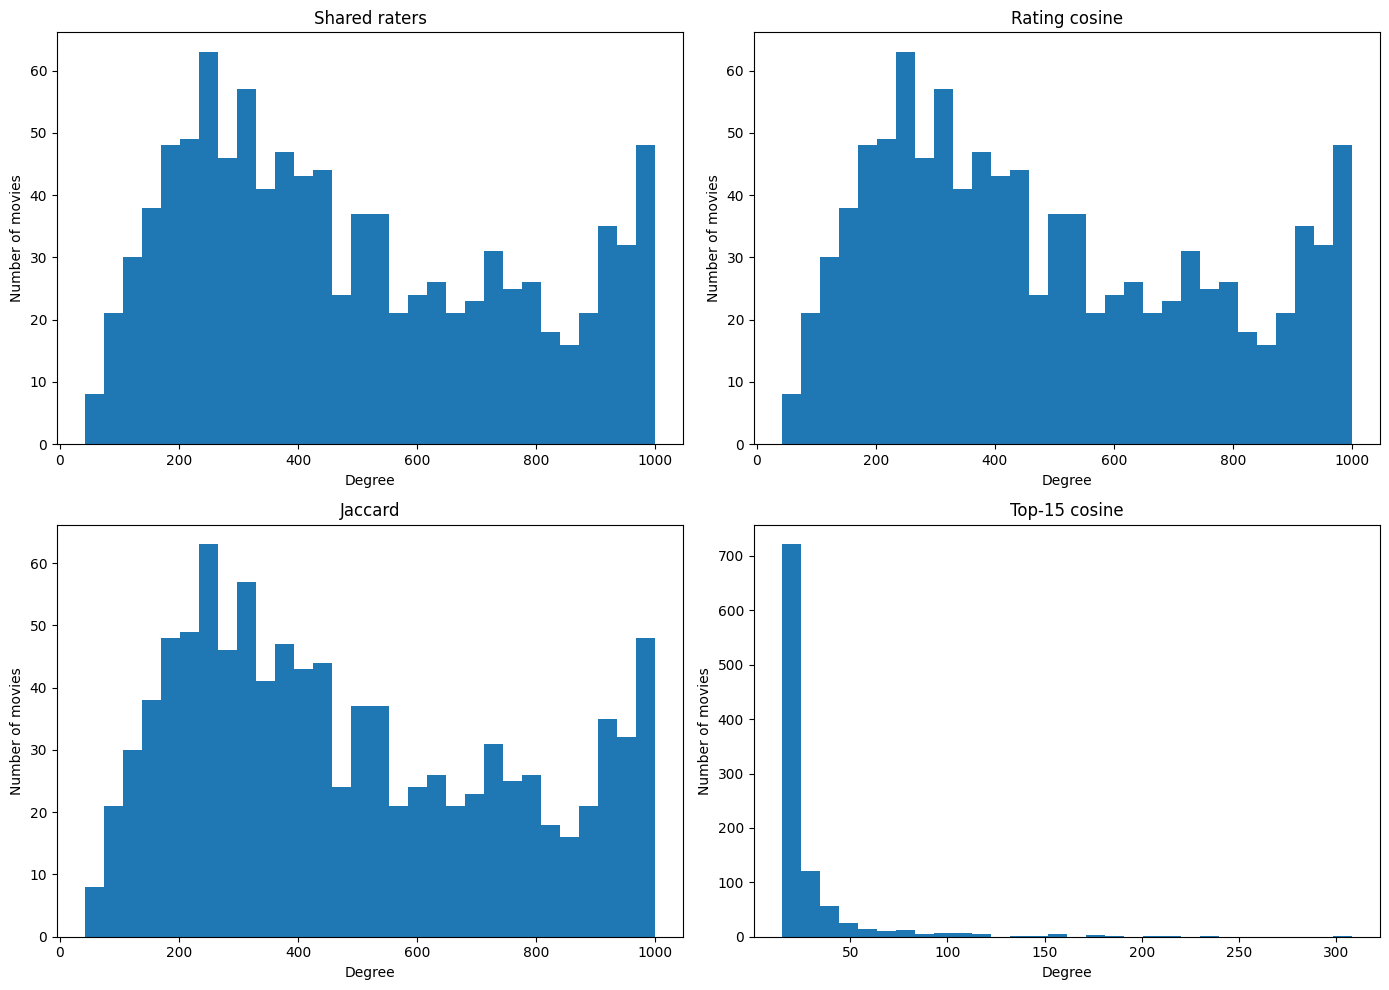

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, G) in zip(axes.flat, graphs.items()):
    degrees = np.array([d for _, d in G.degree()])
    ax.hist(degrees, bins=30)
    ax.set_title(name)
    ax.set_xlabel("Degree")
    ax.set_ylabel("Number of movies")

plt.tight_layout()
plt.show()

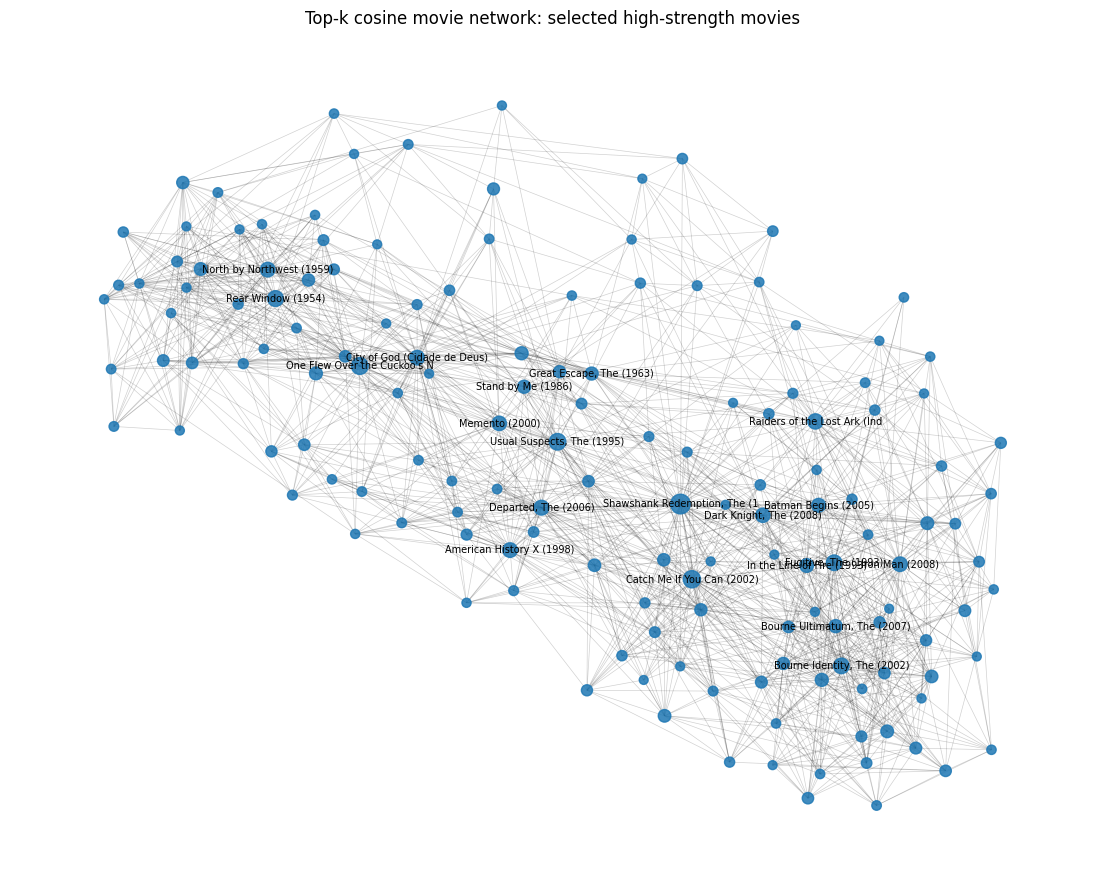

In [26]:
G = G_topk

strength = dict(G.degree(weight="weight"))
display_nodes = sorted(strength, key=strength.get, reverse=True)[:150]
G_display = G.subgraph(display_nodes).copy()

pos = nx.spring_layout(G_display, seed=42, weight="weight", k=0.35)

node_strength = np.array([strength[n] for n in G_display.nodes()])
node_sizes = 20 + 180 * (
    node_strength / max(node_strength.max(), 1e-9)
)

plt.figure(figsize=(14, 11))
nx.draw_networkx_edges(
    G_display, pos, alpha=0.18, width=0.5
)
nx.draw_networkx_nodes(
    G_display, pos, node_size=node_sizes, alpha=0.85
)

# Label only the most connected 20 nodes
label_nodes = sorted(
    G_display.nodes(),
    key=lambda n: strength[n],
    reverse=True
)[:20]

labels = {
    n: G_display.nodes[n]["title"][:28]
    for n in label_nodes
}
nx.draw_networkx_labels(
    G_display, pos, labels=labels, font_size=7
)

plt.title("Top-k cosine movie network: selected high-strength movies")
plt.axis("off")
plt.show()

In [27]:
def graph_summary(G):
    degrees = np.array([d for _, d in G.degree()])
    strengths = np.array([
        d for _, d in G.degree(weight="weight")
    ])

    components = list(nx.connected_components(G))
    largest_component = max((len(c) for c in components), default=0)

    return {
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges(),
        "density": nx.density(G),
        "components": len(components),
        "largest_component_fraction": largest_component / max(G.number_of_nodes(), 1),
        "average_degree": degrees.mean() if len(degrees) else 0,
        "average_strength": strengths.mean() if len(strengths) else 0,
        "average_clustering": nx.average_clustering(G),
    }

summary = pd.DataFrame({
    name: graph_summary(G)
    for name, G in graphs.items()
}).T

summary.round(4)

,nodes,edges,density,components,largest_component_fraction,average_degree,average_strength,average_clustering
Shared raters,1000.0,244612.0,0.4897,1.0,1.0,489.224,2.011764e+06,0.8472
Rating cosine,1000.0,244612.0,0.4897,1.0,1.0,489.224,4.627794e+02,0.8472
Jaccard,1000.0,244612.0,0.4897,1.0,1.0,489.224,7.053190e+01,0.8472
Top-15 cosine,1000.0,13583.0,0.0272,1.0,1.0,27.166,2.617770e+01,0.3492


In [28]:
def centrality_table(G):
    strength = dict(G.degree(weight="weight"))
    degree = dict(G.degree())
    pagerank = nx.pagerank(G, weight="weight")

    result = pd.DataFrame({
        "movieId": list(G.nodes()),
        "degree": [degree[n] for n in G.nodes()],
        "strength": [strength[n] for n in G.nodes()],
        "pagerank": [pagerank[n] for n in G.nodes()],
    })

    result["title"] = result["movieId"].map(
        lambda m: G.nodes[m]["title"]
    )
    return result.sort_values("strength", ascending=False)

top_movies = centrality_table(G_topk)
top_movies.head(20)

,movieId,degree,strength,pagerank,title
108,318,308,298.270586,0.009947,"Shawshank Redemption, The (1994)"
873,5989,230,222.355722,0.007491,Catch Me If You Can (2002)
311,1193,217,210.489529,0.007154,One Flew Over the Cuckoo's Nest (1975)
27,50,209,202.792737,0.006771,"Usual Suspects, The (1995)"
242,904,186,180.682544,0.006209,Rear Window (1954)
853,5418,181,174.440916,0.005949,"Bourne Identity, The (2002)"
150,457,181,174.291195,0.005944,"Fugitive, The (1993)"
314,1198,172,166.370463,0.005713,Raiders of the Lost Ark (Indiana Jones and the...
963,48516,161,156.386454,0.005195,"Departed, The (2006)"
243,908,155,150.643737,0.005184,North by Northwest (1959)


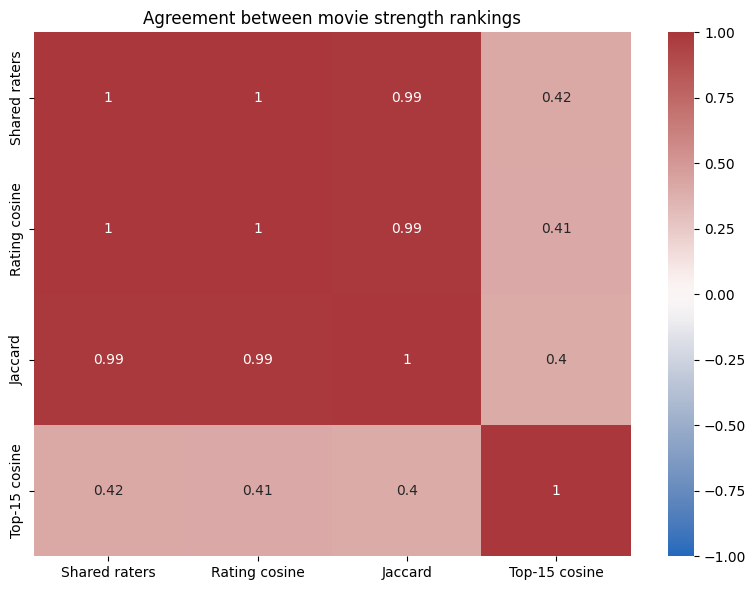

In [29]:
from scipy.stats import spearmanr

rankings = {}
for name, G in graphs.items():
    table = centrality_table(G).set_index("movieId")
    rankings[name] = table["strength"].rank(ascending=False)

rank_df = pd.DataFrame(rankings)
rank_corr = rank_df.corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(rank_corr, annot=True, vmin=-1, vmax=1, cmap="vlag")
plt.title("Agreement between movie strength rankings")
plt.tight_layout()
plt.show()

In [30]:
from networkx.algorithms.community import (
    greedy_modularity_communities,
    modularity
)

communities = list(
    greedy_modularity_communities(G_topk, weight="weight")
)

community_id = {}
for cid, community in enumerate(communities):
    for movie_id in community:
        community_id[movie_id] = cid

print("Communities found:", len(communities))
print(
    "Weighted modularity:",
    modularity(G_topk, communities, weight="weight")
)

community_table = pd.DataFrame({
    "movieId": list(community_id.keys()),
    "community": list(community_id.values())
})

community_table["title"] = community_table["movieId"].map(
    lambda m: G_topk.nodes[m]["title"]
)
community_table["genres"] = community_table["movieId"].map(
    lambda m: G_topk.nodes[m]["genres"]
)

community_table.head(20)

Communities found: 3
Weighted modularity: 0.40692804863766485


,movieId,community,title,genres
0,2,0,Jumanji (1995),Adventure|Children|Fantasy
1,33794,0,Batman Begins (2005),Action|Crime|IMAX
2,3,0,Grumpier Old Men (1995),Comedy|Romance
3,5,0,Father of the Bride Part II (1995),Comedy
4,6,0,Heat (1995),Action|Crime|Thriller
5,2054,0,"Honey, I Shrunk the Kids (1989)",Adventure|Children|Comedy|Fantasy|Sci-Fi
6,1027,0,Robin Hood: Prince of Thieves (1991),Adventure|Drama
7,7,0,Sabrina (1995),Comedy|Romance
8,10,0,GoldenEye (1995),Action|Adventure|Thriller
9,11,0,"American President, The (1995)",Comedy|Drama|Romance


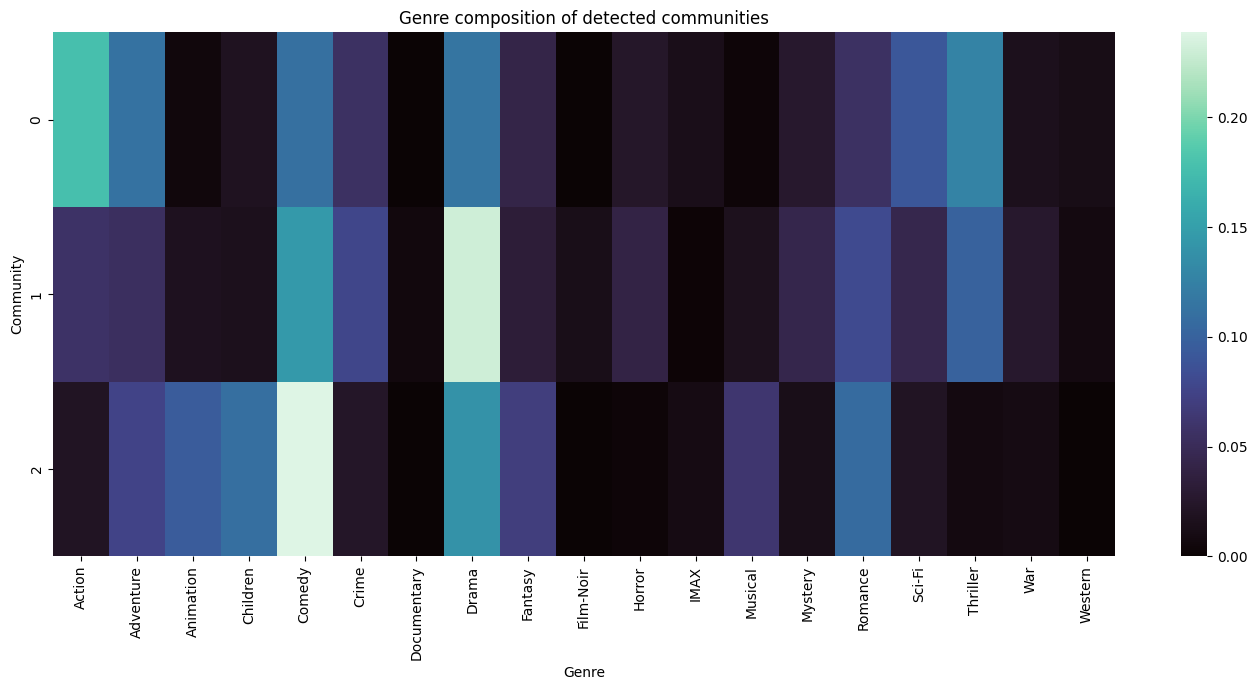

In [31]:
genre_rows = []

for movie_id, info in movie_info.items():
    genres = info.get("genres", "")
    if genres and genres != "(no genres listed)":
        for genre in genres.split("|"):
            genre_rows.append({
                "movieId": int(movie_id),
                "genre": genre
            })

movie_genres = pd.DataFrame(genre_rows)

community_genres = community_table.merge(
    movie_genres, on="movieId", how="left"
)

genre_mix = pd.crosstab(
    community_genres["community"],
    community_genres["genre"],
    normalize="index"
)

plt.figure(figsize=(14, 7))
sns.heatmap(genre_mix, cmap="mako")
plt.title("Genre composition of detected communities")
plt.xlabel("Genre")
plt.ylabel("Community")
plt.tight_layout()
plt.show()

In [32]:
betweenness = nx.betweenness_centrality(
    G_topk, k=min(100, G_topk.number_of_nodes()),
    normalized=True, seed=42, weight=None
)

bridge_movies = pd.DataFrame({
    "movieId": list(betweenness.keys()),
    "betweenness": list(betweenness.values())
})

bridge_movies["title"] = bridge_movies["movieId"].map(
    lambda m: G_topk.nodes[m]["title"]
)

bridge_movies.sort_values("betweenness", ascending=False).head(20)

,movieId,betweenness,title
108,318,0.138877,"Shawshank Redemption, The (1994)"
873,5989,0.067228,Catch Me If You Can (2002)
311,1193,0.054534,One Flew Over the Cuckoo's Nest (1975)
27,50,0.045904,"Usual Suspects, The (1995)"
150,457,0.040204,"Fugitive, The (1993)"
853,5418,0.039241,"Bourne Identity, The (2002)"
963,48516,0.035244,"Departed, The (2006)"
314,1198,0.033764,Raiders of the Lost Ark (Indiana Jones and the...
242,904,0.029890,Rear Window (1954)
982,59315,0.029219,Iron Man (2008)
